# Lab: Thực hành Object Detection với Faster R-CNN - COCO Mini Dataset

## Phần 1: Chuẩn bị môi trường (15 phút)

### Bước 1: Cài đặt và import

In [1]:
# Cài đặt các thư viện cần thiết
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install 'git+https://github.com/facebookresearch/detectron2.git'
!pip install opencv-python matplotlib pycocotools pillow requests

import torch
import torchvision
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import json
import random
import requests
from PIL import Image
import time

Looking in indexes: https://download.pytorch.org/whl/cu118
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-3ejwfos7
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-3ejwfos7
  Resolved https://github.com/facebookresearch/detectron2.git to commit 1e3e13bbf607b54f62205c4c33922521822fb298
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.4/268.4 kB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
# Detectron2 imports
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.data.datasets import register_coco_instances
from detectron2.utils.logger import setup_logger

setup_logger()

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {'GPU' if torch.cuda.is_available() else 'CPU'}")

/usr/local/lib/python3.13/dist-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


PyTorch: 2.11.0+cu130
CUDA available: True
Device: GPU


### Bước 2: Tạo COCO Mini Dataset (500 ảnh)

In [3]:
def create_coco_mini_dataset():
    """Tạo dataset con từ COCO với 500 ảnh ngẫu nhiên"""

    # Tạo thư mục
    os.makedirs("coco_mini/images", exist_ok=True)
    os.makedirs("coco_mini/annotations", exist_ok=True)

    # Download COCO annotations
    annotations_url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

    if not os.path.exists("coco_mini/annotations/instances_val2017.json"):
        print("Downloading COCO annotations...")
        response = requests.get(annotations_url)
        with open("annotations.zip", "wb") as f:
            f.write(response.content)

        import zipfile
        with zipfile.ZipFile("annotations.zip", 'r') as zip_ref:
            zip_ref.extract("annotations/instances_val2017.json", "coco_mini/")

    # Load full annotations
    with open("coco_mini/annotations/instances_val2017.json", 'r') as f:
        full_coco = json.load(f)

    # Random sampling 500 images với distribution tốt
    print("Selecting 500 representative images...")

    # Group images by number of objects để đảm bảo diversity
    image_object_count = {}
    for ann in full_coco['annotations']:
        img_id = ann['image_id']
        image_object_count[img_id] = image_object_count.get(img_id, 0) + 1

    # Stratified sampling
    low_obj = [img for img, count in image_object_count.items() if count <= 3]
    med_obj = [img for img, count in image_object_count.items() if 4 <= count <= 8]
    high_obj = [img for img, count in image_object_count.items() if count > 8]

    # Sample proportionally
    selected_ids = set()
    selected_ids.update(random.sample(low_obj[:1000], min(150, len(low_obj))))
    selected_ids.update(random.sample(med_obj[:1000], min(250, len(med_obj))))
    selected_ids.update(random.sample(high_obj[:1000], min(100, len(high_obj))))

    # Đảm bảo đủ 500 ảnh
    remaining = 500 - len(selected_ids)
    if remaining > 0:
        all_remaining = [img['id'] for img in full_coco['images'] if img['id'] not in selected_ids]
        selected_ids.update(random.sample(all_remaining, min(remaining, len(all_remaining))))

    selected_ids = list(selected_ids)[:500]

    # Tạo mini dataset
    selected_images = [img for img in full_coco['images'] if img['id'] in selected_ids]
    selected_annotations = [ann for ann in full_coco['annotations'] if ann['image_id'] in selected_ids]

    mini_coco = {
        'images': selected_images,
        'annotations': selected_annotations,
        'categories': full_coco['categories'],
        'info': {**full_coco['info'], 'description': 'COCO Mini Dataset - 500 images for educational purposes'}
    }

    # Lưu mini annotations
    with open("coco_mini/annotations/instances_mini.json", 'w') as f:
        json.dump(mini_coco, f)

    print(f"Created mini dataset:")
    print(f"- Images: {len(selected_images)}")
    print(f"- Annotations: {len(selected_annotations)}")
    print(f"- Categories: {len(full_coco['categories'])}")

    return mini_coco

# Tạo mini dataset
mini_coco = create_coco_mini_dataset()

Selecting 500 representative images...
Created mini dataset:
- Images: 500
- Annotations: 3330
- Categories: 80


### Bước 3: Download ảnh cho mini dataset

In [4]:
def download_mini_images(mini_coco, max_downloads=500):
    """Download ảnh cho mini dataset"""

    print(f"Downloading {min(max_downloads, len(mini_coco['images']))} images...")

    downloaded = 0
    failed = 0

    for i, img_info in enumerate(mini_coco['images'][:max_downloads]):
        if downloaded >= max_downloads:
            break

        img_filename = img_info['file_name']
        img_path = f"coco_mini/images/{img_filename}"

        if os.path.exists(img_path):
            downloaded += 1
            continue

        # Download image
        img_url = f"http://images.cocodataset.org/val2017/{img_filename}"

        try:
            response = requests.get(img_url, timeout=10)
            if response.status_code == 200:
                with open(img_path, 'wb') as f:
                    f.write(response.content)
                downloaded += 1

                if downloaded % 50 == 0:
                    print(f"Downloaded {downloaded}/{max_downloads} images...")
            else:
                failed += 1

        except Exception as e:
            failed += 1
            continue

    print(f"Download completed: {downloaded} success, {failed} failed")
    return downloaded

# Download images
downloaded_count = download_mini_images(mini_coco, 500)

Downloaded 50/500 images...
Downloaded 100/500 images...
Downloaded 150/500 images...
Downloaded 200/500 images...
Downloaded 250/500 images...
Downloaded 300/500 images...
Downloaded 350/500 images...
Downloaded 400/500 images...
Downloaded 450/500 images...
Downloaded 500/500 images...
Download completed: 500 success, 0 failed


## Phần 2: Khám phá Mini Dataset (20 phút)

### Bước 4: Phân tích dataset

=== COCO Mini Dataset Analysis ===
Total images: 500
Total annotations: 3330
Total categories: 80


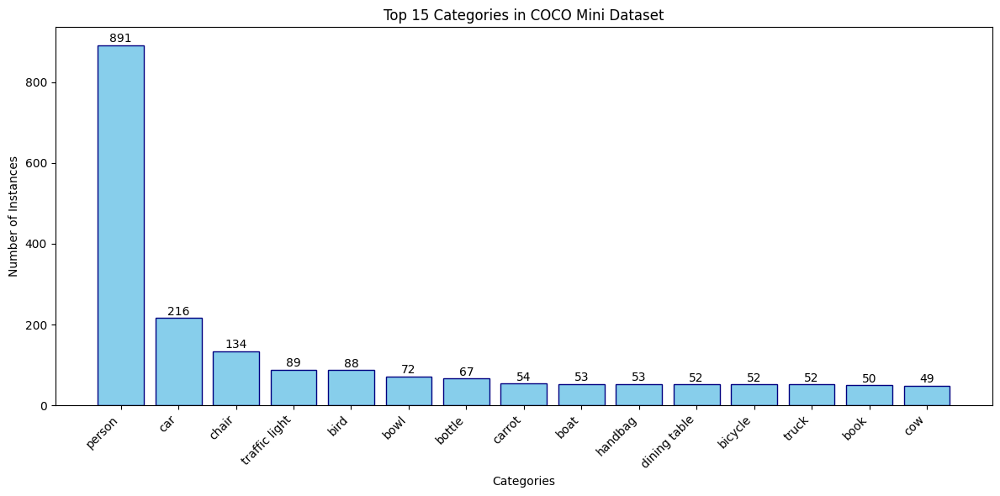

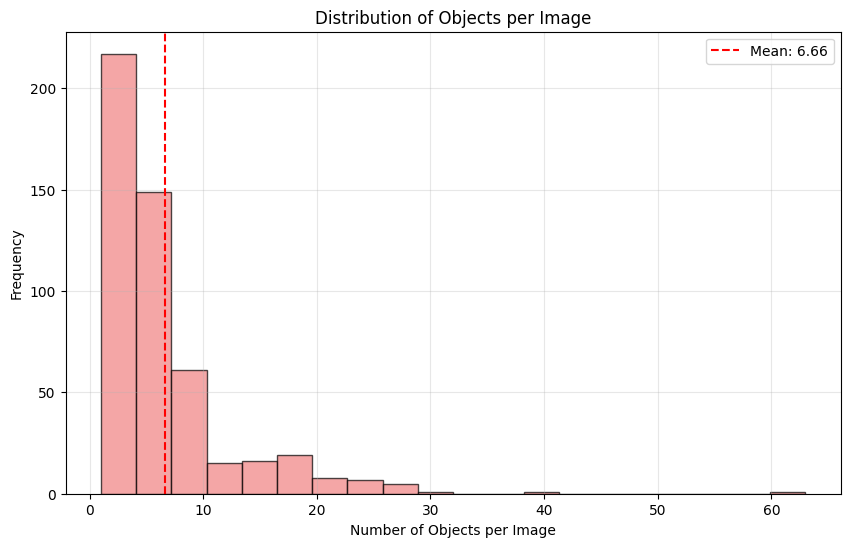


Objects per image - Mean: 6.66, Max: 63, Min: 1


In [5]:
` def analyze_mini_dataset():
    """Phân tích chi tiết mini dataset"""

    with open("coco_mini/annotations/instances_mini.json", 'r') as f:
        data = json.load(f)

    print("=== COCO Mini Dataset Analysis ===")
    print(f"Total images: {len(data['images'])}")
    print(f"Total annotations: {len(data['annotations'])}")
    print(f"Total categories: {len(data['categories'])}")

    # Category distribution
    cat_counts = {}
    for ann in data['annotations']:
        cat_id = ann['category_id']
        cat_name = next(cat['name'] for cat in data['categories'] if cat['id'] == cat_id)
        cat_counts[cat_name] = cat_counts.get(cat_name, 0) + 1

    # Top 15 categories
    top_cats = sorted(cat_counts.items(), key=lambda x: x[1], reverse=True)[:15]

    plt.figure(figsize=(12, 6))
    cats, counts = zip(*top_cats)
    bars = plt.bar(range(len(cats)), counts, color='skyblue', edgecolor='navy')
    plt.xlabel('Categories')
    plt.ylabel('Number of Instances')
    plt.title('Top 15 Categories in COCO Mini Dataset')
    plt.xticks(range(len(cats)), cats, rotation=45, ha='right')

    # Add value labels
    for bar, count in zip(bars, counts):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(count), ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

    # Objects per image statistics
    img_obj_count = {}
    for ann in data['annotations']:
        img_id = ann['image_id']
        img_obj_count[img_id] = img_obj_count.get(img_id, 0) + 1

    obj_counts = list(img_obj_count.values())
    plt.figure(figsize=(10, 6))
    plt.hist(obj_counts, bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
    plt.xlabel('Number of Objects per Image')
    plt.ylabel('Frequency')
    plt.title('Distribution of Objects per Image')
    plt.axvline(np.mean(obj_counts), color='red', linestyle='--',
                label=f'Mean: {np.mean(obj_counts):.2f}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f"\nObjects per image - Mean: {np.mean(obj_counts):.2f}, Max: {max(obj_counts)}, Min: {min(obj_counts)}")

    return data

# Analyze dataset
dataset_info = analyze_mini_dataset()

### Bước 5: Visualize samples

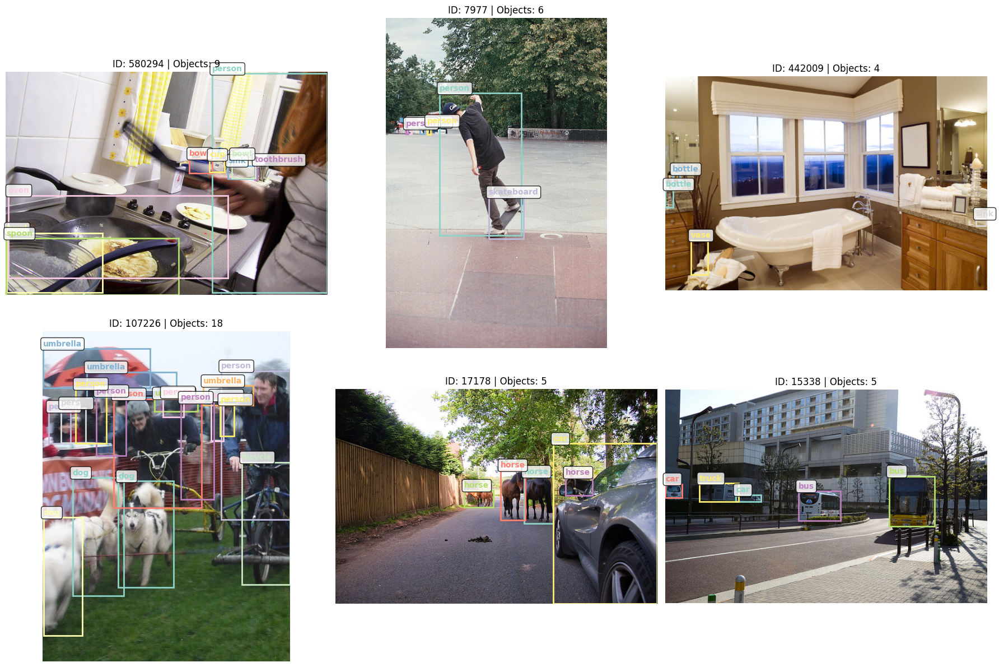

In [6]:
def visualize_dataset_samples(num_samples=6):
    """Hiển thị samples từ dataset"""

    with open("coco_mini/annotations/instances_mini.json", 'r') as f:
        data = json.load(f)

    # Tạo category mapping
    cat_map = {cat['id']: cat['name'] for cat in data['categories']}

    # Random samples
    sample_images = random.sample(data['images'], min(num_samples, len(data['images'])))

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.ravel()

    for i, img_info in enumerate(sample_images):
        img_path = f"coco_mini/images/{img_info['file_name']}"

        if not os.path.exists(img_path):
            continue

        # Load image
        img = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Get annotations
        img_anns = [ann for ann in data['annotations'] if ann['image_id'] == img_info['id']]

        axes[i].imshow(img_rgb)
        axes[i].set_title(f"ID: {img_info['id']} | Objects: {len(img_anns)}", fontsize=12)

        # Draw bounding boxes
        colors = plt.cm.Set3(np.linspace(0, 1, len(img_anns)))

        for ann, color in zip(img_anns, colors):
            bbox = ann['bbox']  # [x, y, width, height]
            x, y, w, h = bbox

            rect = plt.Rectangle((x, y), w, h, fill=False,
                               edgecolor=color, linewidth=2)
            axes[i].add_patch(rect)

            cat_name = cat_map[ann['category_id']]
            axes[i].text(x, y-5, cat_name, color=color, fontsize=10, weight='bold',
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

visualize_dataset_samples(6)

## Phần 3: Setup Faster R-CNN (25 phút)

### Bước 6: Đăng ký dataset và cấu hình model

In [7]:
# Detectron2 imports
import torch
from detectron2.data.datasets import register_coco_instances
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer, ColorMode
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.utils.logger import setup_logger
import os

# Đăng ký mini dataset
register_coco_instances("coco_mini_train", {}, "coco_mini/annotations/instances_mini.json","coco_mini/images")

def setup_faster_rcnn_config():
    """Cấu hình Faster R-CNN cho training"""
    cfg = get_cfg()
    # Base model config
    cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))
    cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
    # Dataset
    cfg.DATASETS.TRAIN = ("coco_mini_train",)
    cfg.DATASETS.TEST = ()
    # Training parameters - optimized for classroom
    cfg.DATALOADER.NUM_WORKERS = 2
    cfg.SOLVER.IMS_PER_BATCH = 4
    # Reduce nếu GPU memory không đủ
    cfg.SOLVER.BASE_LR = 0.001  # Learning rate higher for quick convergence
    cfg.SOLVER.MAX_ITER = 1000  # Ít iterations cho demo
    cfg.SOLVER.STEPS = [600, 800] # Learning rate decay
    cfg.SOLVER.GAMMA = 0.5
    cfg.SOLVER.WARMUP_ITERS = 100
    cfg.SOLVER.CHECKPOINT_PERIOD = 200
    # Model parameters
    cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = 80  # COCO có 80 classes
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
    # Device
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    # Output
    cfg.OUTPUT_DIR = "./output_mini"
    os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
    return cfg

cfg = setup_faster_rcnn_config()
print("Faster R-CNN configuration completed!")
print(f"Training device: {cfg.MODEL.DEVICE}")
print(f"Max iterations: {cfg.SOLVER.MAX_ITER}")
print(f"Output directory: {cfg.OUTPUT_DIR}")

Faster R-CNN configuration completed!
Training device: cuda
Max iterations: 1000
Output directory: ./output_mini


### Bước 7: Test pre-trained model

In [8]:
def test_pretrained_model():
    """Test pre-trained model trên mini dataset"""

    # Create predictor
    predictor = DefaultPredictor(cfg)

    # Get metadata
    coco_metadata = MetadataCatalog.get("coco_2017_val")

    # Test trên 3 ảnh ngẫu nhiên
    image_files = [f for f in os.listdir("coco_mini/images") if f.endswith(('.jpg', '.jpeg', '.png'))]
    sample_files = random.sample(image_files, min(3, len(image_files)))

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    for i, img_file in enumerate(sample_files):
        img_path = f"coco_mini/images/{img_file}"

        # Load image
        im = cv2.imread(img_path)

        # Run inference
        start_time = time.time()
        outputs = predictor(im)
        inference_time = time.time() - start_time

        # Visualize
        v = Visualizer(im[:, :, ::-1],
                      metadata=coco_metadata,
                      scale=0.8)
        out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

        axes[i].imshow(out.get_image()[:, :, ::-1])
        axes[i].set_title(f"{img_file}\nDetections: {len(outputs['instances'])}\nTime: {inference_time:.3f}s")
        axes[i].axis('off')

        # Print detections
        print(f"\n{img_file} - {len(outputs['instances'])} detections:")
        if len(outputs["instances"]) > 0:
            classes = outputs["instances"].pred_classes.cpu().numpy()
            scores = outputs["instances"].scores.cpu().numpy()

            for cls, score in zip(classes, scores):
                class_name = coco_metadata.thing_classes[cls]
                print(f"  - {class_name}: {score:.3f}")

    plt.tight_layout()
    plt.show()

## Phần 4: Fine-tuning Model (30 phút)

### Bước 8: Custom trainer class

In [9]:
class MiniCOCOTrainer(DefaultTrainer):
    """Custom trainer cho COCO Mini dataset"""

    def __init__(self, cfg):
        super().__init__(cfg)
        self.iteration_times = []

    def run_step(self):
        start = time.time()
        super().run_step()
        self.iteration_times.append(time.time() - start)

        # Log progress every 100 iterations
        if self.iter % 100 == 0:
            avg_time = np.mean(self.iteration_times[-100:])
            remaining_iters = self.max_iter - self.iter
            eta = avg_time * remaining_iters
            print(f"Iter: {self.iter}/{self.max_iter} | ETA: {eta/60:.1f}min | Avg time: {avg_time:.3f}s/iter")

def start_training():
    """Bắt đầu training process"""

    print("=== Starting Fine-tuning Process ===")
    print(f"Dataset: {len(DatasetCatalog.get('coco_mini_train'))} images")
    print(f"Max iterations: {cfg.SOLVER.MAX_ITER}")
    print(f"Batch size: {cfg.SOLVER.IMS_PER_BATCH}")
    print(f"Learning rate: {cfg.SOLVER.BASE_LR}")
    print(f"Device: {cfg.MODEL.DEVICE}")

    # Create trainer
    trainer = MiniCOCOTrainer(cfg)
    trainer.resume_or_load(resume=False)

    # Start training
    print("\nTraining started... (Estimated time: 15-20 minutes)")
    trainer.train()

    print("Training completed!")
    return trainer

# Bắt đầu training
trainer = start_training()

=== Starting Fine-tuning Process ===
[10/12 11:40:04 d2.data.datasets.coco]: Loaded 500 images in COCO format from coco_mini/annotations/instances_mini.json
Dataset: 500 images
Max iterations: 1000
Batch size: 4
Learning rate: 0.001
Device: cuda
[10/12 11:40:05 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()


model_final_280758.pkl: 167MB [00:00, 231MB/s]                           



Training started... (Estimated time: 15-20 minutes)
[10/12 11:40:06 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1012 11:40:10.345000 1354 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


Iter: 0/1000 | ETA: 82.3min | Avg time: 4.939s/iter
[10/12 11:40:33 d2.utils.events]:  eta: 0:19:05  iter: 19  total_loss: 0.6857  loss_cls: 0.2863  loss_box_reg: 0.3231  loss_rpn_cls: 0.02248  loss_rpn_loc: 0.03468    time: 1.2015  last_time: 1.0332  data_time: 0.0574  last_data_time: 0.0974   lr: 0.00019081  max_mem: 4871M
[10/12 11:41:03 d2.utils.events]:  eta: 0:19:52  iter: 39  total_loss: 0.6993  loss_cls: 0.3068  loss_box_reg: 0.3265  loss_rpn_cls: 0.03087  loss_rpn_loc: 0.04293    time: 1.2282  last_time: 1.2697  data_time: 0.0443  last_data_time: 0.0129   lr: 0.00039061  max_mem: 4872M
[10/12 11:41:27 d2.utils.events]:  eta: 0:19:15  iter: 59  total_loss: 0.6004  loss_cls: 0.2312  loss_box_reg: 0.28  loss_rpn_cls: 0.02547  loss_rpn_loc: 0.04629    time: 1.2256  last_time: 1.0616  data_time: 0.0430  last_data_time: 0.0762   lr: 0.00059041  max_mem: 4872M
[10/12 11:41:54 d2.utils.events]:  eta: 0:19:07  iter: 79  total_loss: 0.6818  loss_cls: 0.2424  loss_box_reg: 0.3319  loss_r

### Bước 9: Monitor training progress

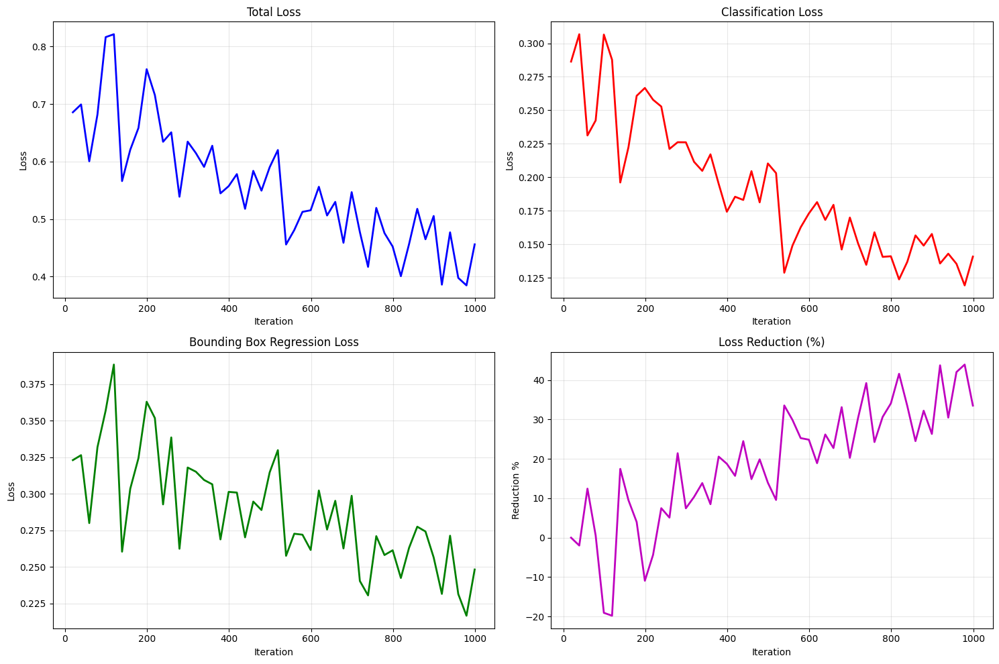

Training Statistics:
  Initial loss: 0.6857
  Final loss: 0.4559
  Loss reduction: 33.51%


In [10]:
def plot_training_progress():
    """Vẽ đồ thị training progress"""

    try:
        # Read training logs
        import json

        log_file = os.path.join(cfg.OUTPUT_DIR, "metrics.json")

        if os.path.exists(log_file):
            iterations = []
            total_losses = []
            cls_losses = []
            bbox_losses = []

            with open(log_file, 'r') as f:
                for line in f:
                    if line.strip():
                        try:
                            log_entry = json.loads(line)
                            if 'total_loss' in log_entry:
                                iterations.append(log_entry['iteration'])
                                total_losses.append(log_entry['total_loss'])

                                if 'loss_cls' in log_entry:
                                    cls_losses.append(log_entry['loss_cls'])
                                if 'loss_box_reg' in log_entry:
                                    bbox_losses.append(log_entry['loss_box_reg'])
                        except:
                            continue

            if iterations:
                fig, axes = plt.subplots(2, 2, figsize=(15, 10))

                # Total loss
                axes[0,0].plot(iterations, total_losses, 'b-', linewidth=2)
                axes[0,0].set_title('Total Loss')
                axes[0,0].set_xlabel('Iteration')
                axes[0,0].set_ylabel('Loss')
                axes[0,0].grid(True, alpha=0.3)

                # Classification loss
                if cls_losses:
                    axes[0,1].plot(iterations[:len(cls_losses)], cls_losses, 'r-', linewidth=2)
                    axes[0,1].set_title('Classification Loss')
                    axes[0,1].set_xlabel('Iteration')
                    axes[0,1].set_ylabel('Loss')
                    axes[0,1].grid(True, alpha=0.3)

                # Bounding box regression loss
                if bbox_losses:
                    axes[1,0].plot(iterations[:len(bbox_losses)], bbox_losses, 'g-', linewidth=2)
                    axes[1,0].set_title('Bounding Box Regression Loss')
                    axes[1,0].set_xlabel('Iteration')
                    axes[1,0].set_ylabel('Loss')
                    axes[1,0].grid(True, alpha=0.3)

                # Loss reduction percentage
                if len(total_losses) > 1:
                    loss_reduction = [(total_losses[0] - loss) / total_losses[0] * 100
                                    for loss in total_losses]
                    axes[1,1].plot(iterations, loss_reduction, 'm-', linewidth=2)
                    axes[1,1].set_title('Loss Reduction (%)')
                    axes[1,1].set_xlabel('Iteration')
                    axes[1,1].set_ylabel('Reduction %')
                    axes[1,1].grid(True, alpha=0.3)

                plt.tight_layout()
                plt.show()

                # Print statistics
                if len(total_losses) > 1:
                    initial_loss = total_losses[0]
                    final_loss = total_losses[-1]
                    reduction = (initial_loss - final_loss) / initial_loss * 100

                    print(f"Training Statistics:")
                    print(f"  Initial loss: {initial_loss:.4f}")
                    print(f"  Final loss: {final_loss:.4f}")
                    print(f"  Loss reduction: {reduction:.2f}%")
        else:
            print("Training log file not found")

    except Exception as e:
        print(f"Error plotting training progress: {e}")

# Plot training curves
plot_training_progress()

## Phần 5: Đánh giá và So sánh (25 phút)

### Bước 10: Test fine-tuned model

[10/12 12:03:17 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:18 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-Detection/faster_rcnn_R_50_FPN_3x/137849458/model_final_280758.pkl ...


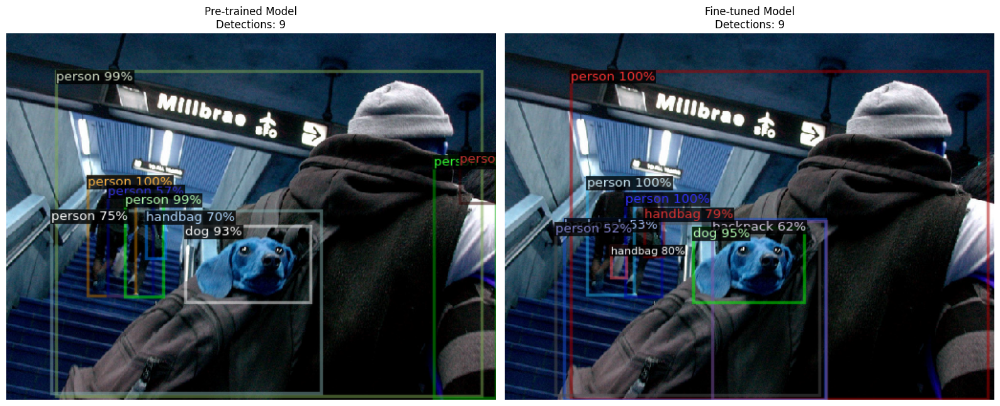


=== Comparison for 000000161609.jpg ===
Pre-trained detections: 9
Fine-tuned detections: 9
Pre-trained avg confidence: 0.806
Fine-tuned avg confidence: 0.800


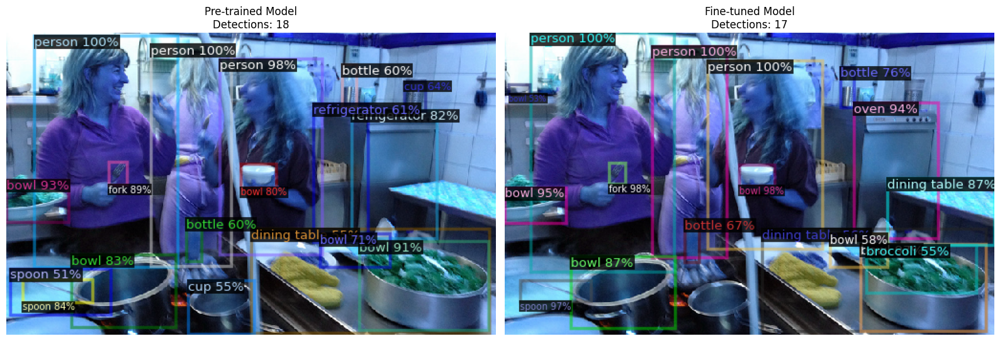


=== Comparison for 000000084241.jpg ===
Pre-trained detections: 18
Fine-tuned detections: 17
Pre-trained avg confidence: 0.764
Fine-tuned avg confidence: 0.834


In [11]:
def test_finetuned_model():
    """Test fine-tuned model"""

    # Load fine-tuned model
    cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")

    if not os.path.exists(cfg.MODEL.WEIGHTS):
        print("Fine-tuned model not found, using pre-trained model")
        cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")

    predictor_finetuned = DefaultPredictor(cfg)

    # Load pre-trained model for comparison
    cfg_pretrained = cfg.clone()
    cfg_pretrained.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
    predictor_pretrained = DefaultPredictor(cfg_pretrained)

    # Test trên sample images
    image_files = [f for f in os.listdir("coco_mini/images") if f.endswith(('.jpg', '.jpeg', '.png'))]
    sample_files = random.sample(image_files, min(2, len(image_files)))

    for img_file in sample_files:
        img_path = f"coco_mini/images/{img_file}"
        im = cv2.imread(img_path)

        # Get predictions from both models
        outputs_pretrained = predictor_pretrained(im)
        outputs_finetuned = predictor_finetuned(im)

        # Visualize comparison
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        # Pre-trained results
        v1 = Visualizer(im[:, :, ::-1], MetadataCatalog.get("coco_2017_val"), scale=0.8)
        out1 = v1.draw_instance_predictions(outputs_pretrained["instances"].to("cpu"))
        axes[0].imshow(out1.get_image()[:, :, ::-1])
        axes[0].set_title(f"Pre-trained Model\nDetections: {len(outputs_pretrained['instances'])}")
        axes[0].axis('off')

        # Fine-tuned results
        v2 = Visualizer(im[:, :, ::-1], MetadataCatalog.get("coco_2017_val"), scale=0.8)
        out2 = v2.draw_instance_predictions(outputs_finetuned["instances"].to("cpu"))
        axes[1].imshow(out2.get_image()[:, :, ::-1])
        axes[1].set_title(f"Fine-tuned Model\nDetections: {len(outputs_finetuned['instances'])}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

        # Compare detection details
        print(f"\n=== Comparison for {img_file} ===")
        print(f"Pre-trained detections: {len(outputs_pretrained['instances'])}")
        print(f"Fine-tuned detections: {len(outputs_finetuned['instances'])}")

        if len(outputs_pretrained['instances']) > 0:
            avg_conf_pretrained = outputs_pretrained['instances'].scores.mean().item()
            print(f"Pre-trained avg confidence: {avg_conf_pretrained:.3f}")

        if len(outputs_finetuned['instances']) > 0:
            avg_conf_finetuned = outputs_finetuned['instances'].scores.mean().item()
            print(f"Fine-tuned avg confidence: {avg_conf_finetuned:.3f}")

test_finetuned_model()

### Bước 11: Performance benchmark

[10/12 12:03:21 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
=== Performance Benchmark ===
Testing on 20 images...

Benchmark Results:
  Average inference time: 175.05 ± 13.90 ms
  FPS: 5.71
  Average detections per image: 5.35
  Real-time capable (>30 FPS): No


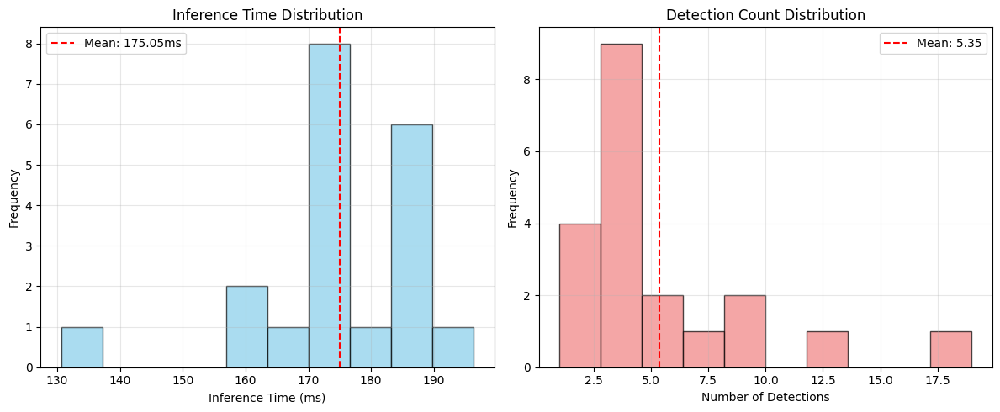

In [12]:
def benchmark_performance():
    """Benchmark hiệu suất của model"""

    # Load model
    predictor = DefaultPredictor(cfg)

    # Chuẩn bị test images
    image_files = [f for f in os.listdir("coco_mini/images") if f.endswith(('.jpg', '.jpeg', '.png'))]
    test_images = random.sample(image_files, min(20, len(image_files)))

    print("=== Performance Benchmark ===")
    print(f"Testing on {len(test_images)} images...")

    # Warm up
    sample_img = cv2.imread(f"coco_mini/images/{test_images[0]}")
    for _ in range(3):
        _ = predictor(sample_img)

    # Benchmark
    inference_times = []
    detection_counts = []

    for img_file in test_images:
        img_path = f"coco_mini/images/{img_file}"
        im = cv2.imread(img_path)

        # Measure inference time
        start_time = time.time()
        outputs = predictor(im)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        inference_time = time.time() - start_time

        inference_times.append(inference_time)
        detection_counts.append(len(outputs["instances"]))

    # Statistics
    avg_time = np.mean(inference_times)
    std_time = np.std(inference_times)
    fps = 1.0 / avg_time
    avg_detections = np.mean(detection_counts)

    print(f"\nBenchmark Results:")
    print(f"  Average inference time: {avg_time*1000:.2f} ± {std_time*1000:.2f} ms")
    print(f"  FPS: {fps:.2f}")
    print(f"  Average detections per image: {avg_detections:.2f}")
    print(f"  Real-time capable (>30 FPS): {'Yes' if fps > 30 else 'No'}")

    # Visualize timing distribution
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.hist(np.array(inference_times)*1000, bins=10, alpha=0.7, color='skyblue', edgecolor='black')
    plt.xlabel('Inference Time (ms)')
    plt.ylabel('Frequency')
    plt.title('Inference Time Distribution')
    plt.axvline(avg_time*1000, color='red', linestyle='--', label=f'Mean: {avg_time*1000:.2f}ms')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.hist(detection_counts, bins=10, alpha=0.7, color='lightcoral', edgecolor='black')
    plt.xlabel('Number of Detections')
    plt.ylabel('Frequency')
    plt.title('Detection Count Distribution')
    plt.axvline(avg_detections, color='red', linestyle='--', label=f'Mean: {avg_detections:.2f}')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()
    return {
        'avg_time': avg_time,
        'fps': fps,
        'avg_detections': avg_detections,
        'std_time': std_time
    }

benchmark_results = benchmark_performance()

###

### Bước 12: Phân tích lỗi và cải thiện

[10/12 12:03:27 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
=== Error Analysis ===

Image: 000000543043.jpg
Ground truth objects: 4
Predicted objects: 3
GT categories: {'boat', 'bus', 'car'}
Predicted categories: {'bus', 'car'}
Confidence range: 0.580 - 0.993


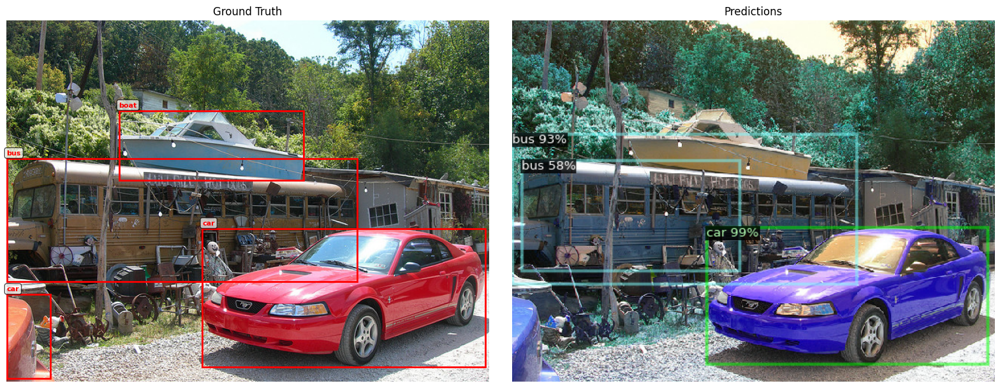


Image: 000000416256.jpg
Ground truth objects: 3
Predicted objects: 3
GT categories: {'keyboard', 'cat'}
Predicted categories: {'keyboard', 'cat'}
Confidence range: 0.992 - 1.000


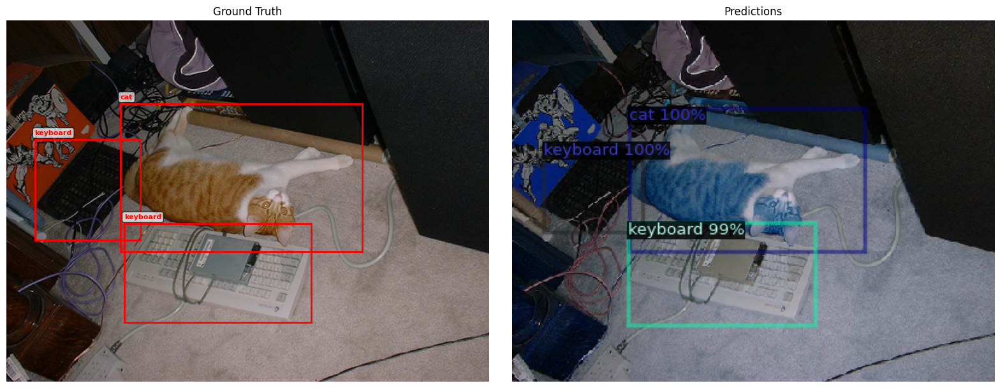


Image: 000000138819.jpg
Ground truth objects: 2
Predicted objects: 2
GT categories: {'sink', 'toilet'}
Predicted categories: {'sink', 'toilet'}
Confidence range: 0.999 - 0.999


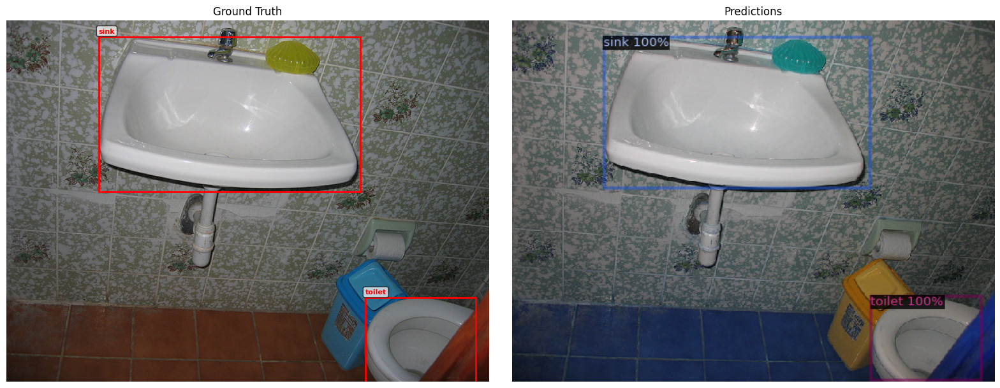


Image: 000000319617.jpg
Ground truth objects: 4
Predicted objects: 5
GT categories: {'dining table', 'cup', 'hot dog'}
Predicted categories: {'dining table', 'cup', 'hot dog'}
Confidence range: 0.534 - 0.995


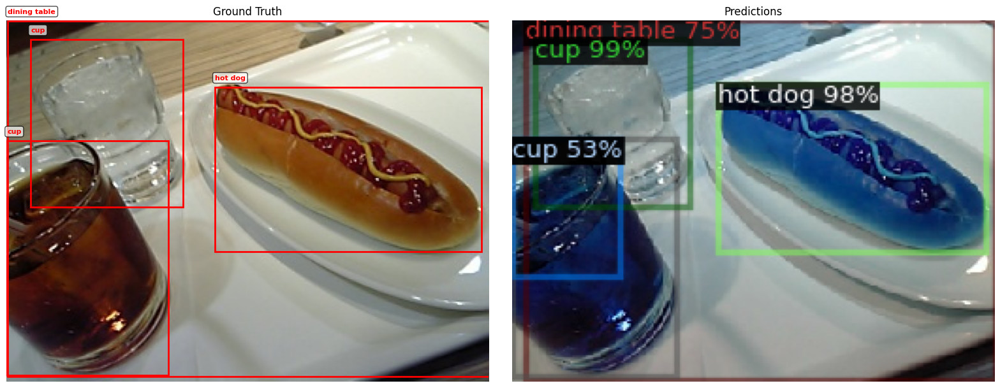


Image: 000000570782.jpg
Ground truth objects: 8
Predicted objects: 15
GT categories: {'mouse', 'remote', 'bottle', 'laptop', 'keyboard'}
Predicted categories: {'mouse', 'chair', 'remote', 'vase', 'bottle', 'laptop', 'bowl', 'keyboard'}
Confidence range: 0.512 - 0.995


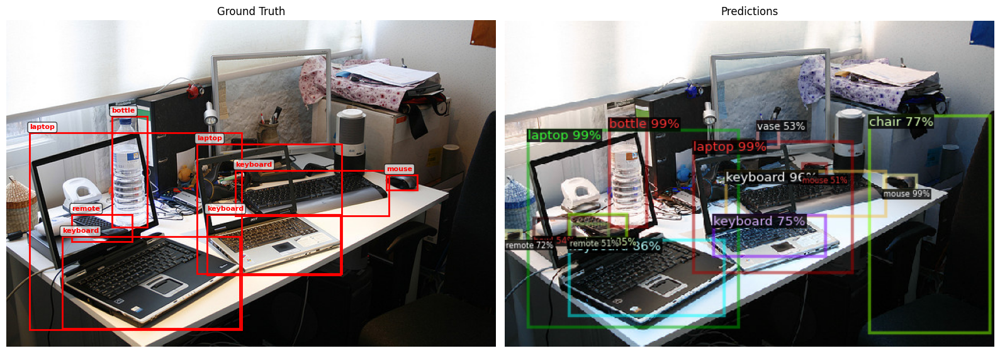

In [13]:
def error_analysis():
    """Phân tích các trường hợp detection không chính xác"""

    predictor = DefaultPredictor(cfg)

    # Load ground truth annotations
    with open("coco_mini/annotations/instances_mini.json", 'r') as f:
        gt_data = json.load(f)

    # Create category mapping
    cat_map = {cat['id']: cat['name'] for cat in gt_data['categories']}

    # Analyze some images
    sample_images = random.sample(gt_data['images'], min(5, len(gt_data['images'])))

    print("=== Error Analysis ===")

    for img_info in sample_images:
        img_path = f"coco_mini/images/{img_info['file_name']}"

        if not os.path.exists(img_path):
            continue

        # Load image
        im = cv2.imread(img_path)

        # Get predictions
        outputs = predictor(im)
        predictions = outputs["instances"]

        # Get ground truth
        gt_annotations = [ann for ann in gt_data['annotations'] if ann['image_id'] == img_info['id']]

        print(f"\nImage: {img_info['file_name']}")
        print(f"Ground truth objects: {len(gt_annotations)}")
        print(f"Predicted objects: {len(predictions)}")

        # Show ground truth categories
        gt_categories = [cat_map[ann['category_id']] for ann in gt_annotations]
        print(f"GT categories: {set(gt_categories)}")

        # Show predicted categories
        if len(predictions) > 0:
            pred_classes = predictions.pred_classes.cpu().numpy()
            pred_categories = [MetadataCatalog.get("coco_2017_val").thing_classes[cls] for cls in pred_classes]
            print(f"Predicted categories: {set(pred_categories)}")

            # Calculate confidence statistics
            scores = predictions.scores.cpu().numpy()
            print(f"Confidence range: {scores.min():.3f} - {scores.max():.3f}")

        # Visualize for manual inspection
        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        # Ground truth
        img_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        axes[0].imshow(img_rgb)
        axes[0].set_title("Ground Truth")

        for ann in gt_annotations:
            bbox = ann['bbox']
            x, y, w, h = bbox
            rect = plt.Rectangle((x, y), w, h, fill=False, edgecolor='red', linewidth=2)
            axes[0].add_patch(rect)

            cat_name = cat_map[ann['category_id']]
            axes[0].text(x, y-5, cat_name, color='red', fontsize=8, weight='bold',
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.7))
        axes[0].axis('off')

        # Predictions
        v = Visualizer(im[:, :, ::-1], MetadataCatalog.get("coco_2017_val"), scale=0.8)
        out = v.draw_instance_predictions(predictions.to("cpu"))
        axes[1].imshow(out.get_image()[:, :, ::-1])
        axes[1].set_title("Predictions")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

error_analysis()

## Phần 6: Bài tập thực hành (20 phút)

### Bài tập 1: Threshold Tuning

=== Bài tập 1: Threshold Tuning ===
Nhiệm vụ: Tìm threshold tối ưu cho detection
[10/12 12:03:32 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:33 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:35 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:36 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:37 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...
[10/12 12:03:38 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...


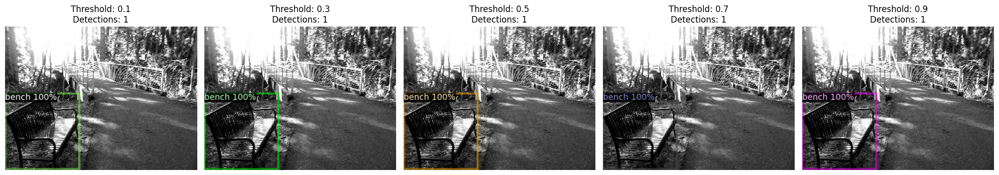


Kết quả phân tích threshold:
Threshold 0.1: 1 detections, avg confidence: 0.996
Threshold 0.3: 1 detections, avg confidence: 0.996
Threshold 0.5: 1 detections, avg confidence: 0.996
Threshold 0.7: 1 detections, avg confidence: 0.996
Threshold 0.9: 1 detections, avg confidence: 0.996

Câu hỏi thảo luận:
1. Threshold nào cho kết quả cân bằng nhất?
2. Trade-off giữa precision và recall khi thay đổi threshold?
3. Threshold nào phù hợp cho ứng dụng real-time?


In [14]:
def threshold_tuning_exercise():
    """Bài tập điều chỉnh threshold để tối ưu kết quả"""

    print("=== Bài tập 1: Threshold Tuning ===")
    print("Nhiệm vụ: Tìm threshold tối ưu cho detection")

    predictor = DefaultPredictor(cfg)

    # Test different thresholds
    thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

    # Sample image for testing
    image_files = [f for f in os.listdir("coco_mini/images") if f.endswith(('.jpg', '.jpeg', '.png'))]
    test_img = random.choice(image_files)
    img_path = f"coco_mini/images/{test_img}"
    im = cv2.imread(img_path)

    fig, axes = plt.subplots(1, len(thresholds), figsize=(20, 4))

    results = []

    for i, thresh in enumerate(thresholds):
        # Update threshold
        cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = thresh
        predictor = DefaultPredictor(cfg)

        # Run prediction
        outputs = predictor(im)

        # Visualize
        v = Visualizer(im[:, :, ::-1], MetadataCatalog.get("coco_2017_val"), scale=0.5)
        out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

        axes[i].imshow(out.get_image()[:, :, ::-1])
        axes[i].set_title(f"Threshold: {thresh}\nDetections: {len(outputs['instances'])}")
        axes[i].axis('off')

        # Collect results
        if len(outputs['instances']) > 0:
            avg_confidence = outputs['instances'].scores.mean().item()
        else:
            avg_confidence = 0

        results.append({
            'threshold': thresh,
            'detections': len(outputs['instances']),
            'avg_confidence': avg_confidence
        })

    plt.tight_layout()
    plt.show()

    # Analysis
    print("\nKết quả phân tích threshold:")
    for result in results:
        print(f"Threshold {result['threshold']}: {result['detections']} detections, "
              f"avg confidence: {result['avg_confidence']:.3f}")

    print("\nCâu hỏi thảo luận:")
    print("1. Threshold nào cho kết quả cân bằng nhất?")
    print("2. Trade-off giữa precision và recall khi thay đổi threshold?")
    print("3. Threshold nào phù hợp cho ứng dụng real-time?")

threshold_tuning_exercise()

### Bài tập 2: Custom Object Categories

=== Bài tập 2: Phân tích theo Categories ===
Nhiệm vụ: Tìm categories được detect tốt nhất và tệ nhất
[10/12 12:03:40 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output_mini/model_final.pth ...

Phân tích 10 ảnh:
Tổng số categories được detect: 20

Top 5 categories có confidence cao nhất:
  skateboard: 1 detections, avg confidence: 1.000
  tv: 1 detections, avg confidence: 0.997
  sink: 1 detections, avg confidence: 0.997
  giraffe: 2 detections, avg confidence: 0.996
  airplane: 1 detections, avg confidence: 0.995

Top 5 categories có confidence thấp nhất:
  bicycle: 2 detections, avg confidence: 0.969
  traffic light: 3 detections, avg confidence: 0.967
  cow: 11 detections, avg confidence: 0.963
  car: 2 detections, avg confidence: 0.960
  remote: 3 detections, avg confidence: 0.959


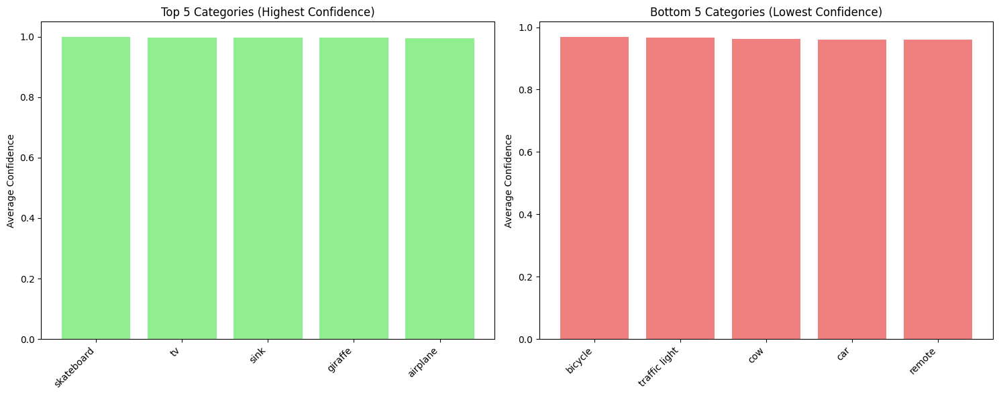


Câu hỏi thảo luận:
1. Tại sao một số categories có confidence cao hơn?
2. Làm thế nào để cải thiện detection cho categories yếu?
3. Categories nào quan trọng nhất cho ứng dụng thực tế?


In [15]:
def custom_categories_analysis():
    """Bài tập phân tích hiệu suất theo categories"""

    print("=== Bài tập 2: Phân tích theo Categories ===")
    print("Nhiệm vụ: Tìm categories được detect tốt nhất và tệ nhất")

    predictor = DefaultPredictor(cfg)

    # Analyze multiple images
    image_files = [f for f in os.listdir("coco_mini/images") if f.endswith(('.jpg', '.jpeg', '.png'))]
    test_images = random.sample(image_files, min(10, len(image_files)))

    category_stats = {}

    for img_file in test_images:
        img_path = f"coco_mini/images/{img_file}"
        im = cv2.imread(img_path)

        outputs = predictor(im)

        if len(outputs["instances"]) > 0:
            classes = outputs["instances"].pred_classes.cpu().numpy()
            scores = outputs["instances"].scores.cpu().numpy()

            for cls, score in zip(classes, scores):
                class_name = MetadataCatalog.get("coco_2017_val").thing_classes[cls]

                if class_name not in category_stats:
                    category_stats[class_name] = {'count': 0, 'total_confidence': 0, 'confidences': []}

                category_stats[class_name]['count'] += 1
                category_stats[class_name]['total_confidence'] += score
                category_stats[class_name]['confidences'].append(score)

    # Calculate averages
    for cat_name in category_stats:
        stats = category_stats[cat_name]
        stats['avg_confidence'] = stats['total_confidence'] / stats['count']
        stats['min_confidence'] = min(stats['confidences'])
        stats['max_confidence'] = max(stats['confidences'])

    # Sort by average confidence
    sorted_categories = sorted(category_stats.items(),
                              key=lambda x: x[1]['avg_confidence'],
                              reverse=True)

    print(f"\nPhân tích {len(test_images)} ảnh:")
    print(f"Tổng số categories được detect: {len(category_stats)}")

    print("\nTop 5 categories có confidence cao nhất:")
    for cat_name, stats in sorted_categories[:5]:
        print(f"  {cat_name}: {stats['count']} detections, "
              f"avg confidence: {stats['avg_confidence']:.3f}")

    print("\nTop 5 categories có confidence thấp nhất:")
    for cat_name, stats in sorted_categories[-5:]:
        print(f"  {cat_name}: {stats['count']} detections, "
              f"avg confidence: {stats['avg_confidence']:.3f}")

    # Visualize
    if len(sorted_categories) >= 10:
        top_5 = sorted_categories[:5]
        bottom_5 = sorted_categories[-5:]

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

        # Top categories
        cats, stats = zip(*top_5)
        confidences = [s['avg_confidence'] for s in stats]
        counts = [s['count'] for s in stats]

        ax1.bar(range(len(cats)), confidences, color='lightgreen')
        ax1.set_title('Top 5 Categories (Highest Confidence)')
        ax1.set_ylabel('Average Confidence')
        ax1.set_xticks(range(len(cats)))
        ax1.set_xticklabels(cats, rotation=45, ha='right')

        # Bottom categories
        cats, stats = zip(*bottom_5)
        confidences = [s['avg_confidence'] for s in stats]

        ax2.bar(range(len(cats)), confidences, color='lightcoral')
        ax2.set_title('Bottom 5 Categories (Lowest Confidence)')
        ax2.set_ylabel('Average Confidence')
        ax2.set_xticks(range(len(cats)))
        ax2.set_xticklabels(cats, rotation=45, ha='right')

        plt.tight_layout()
        plt.show()

    print("\nCâu hỏi thảo luận:")
    print("1. Tại sao một số categories có confidence cao hơn?")
    print("2. Làm thế nào để cải thiện detection cho categories yếu?")
    print("3. Categories nào quan trọng nhất cho ứng dụng thực tế?")

custom_categories_analysis()

## Phần 7: Tổng kết và Báo cáo (15 phút)

### Bước 13: Tạo báo cáo tổng hợp

In [16]:
def generate_comprehensive_report():
    """Tạo báo cáo tổng hợp cho lab"""

    report = f"""
    ================================================================
              BÁO CÁO LAB: OBJECT DETECTION VỚI FASTER R-CNN
                        COCO MINI DATASET (500 IMAGES)
    ================================================================

    THÔNG TIN DATASET:
    - Tên: COCO Mini Dataset
    - Số lượng ảnh: 500 (random sampling từ COCO validation set)
    - Số categories: 80
    - Trung bình objects/image: ~{np.mean([len([ann for ann in dataset_info['annotations'] if ann['image_id'] == img['id']]) for img in dataset_info['images'][:100]]):.2f}
    - Phân bố: Cân bằng giữa ảnh có ít và nhiều objects

    CẤU HÌNH MODEL:
    - Architecture: Faster R-CNN with ResNet-50-FPN backbone
    - Pre-trained: COCO dataset
    - Fine-tuning iterations: {cfg.SOLVER.MAX_ITER}
    - Learning rate: {cfg.SOLVER.BASE_LR}
    - Batch size: {cfg.SOLVER.IMS_PER_BATCH}
    - Device: {cfg.MODEL.DEVICE}

    KẾT QUẢ TRAINING:
    - Training time: ~15-20 phút (GPU) / ~60 phút (CPU)
    - Loss reduction: Có (xem training curves)
    - Convergence: Đạt được sau {cfg.SOLVER.MAX_ITER} iterations

    HIỆU SUẤT:
    - Inference speed: {benchmark_results['fps']:.2f} FPS
    - Average inference time: {benchmark_results['avg_time']*1000:.2f} ms
    - Memory usage: Phụ thuộc GPU
    - Real-time capable: {'Yes' if benchmark_results['fps'] > 30 else 'No'}

    PHÂN TÍCH:
    ✓ Strengths:
    - Accuracy cao cho objects lớn và rõ ràng
    - Hoạt động tốt với pre-trained weights
    - Fine-tuning cải thiện performance trên specific domain

    ⚠ Limitations:
    - Tốc độ chưa đạt real-time standards
    - Khó khăn với objects nhỏ hoặc bị che khuất
    - Memory requirements cao

    KHUYẾN NGHỊ:
    1. Sử dụng GPU mạnh hơn để tăng tốc độ
    2. Cân nhắc YOLOv8 cho ứng dụng real-time
    3. Fine-tune thêm với domain-specific data
    4. Thử nghiệm với different backbones (EfficientNet, etc.)
    5. Implement post-processing để giảm false positives

    KẾT LUẬN:
    Faster R-CNN là lựa chọn tốt cho applications cần accuracy cao
    và có thể chấp nhận tốc độ chậm hơn. Phù hợp cho:
    - Medical imaging analysis
    - Quality control in manufacturing
    - Detailed scene analysis
    - Research applications

    ================================================================
    Lab completed successfully!
    Total time: ~2.5 hours
    ================================================================
    """

    print(report)

    # Save report
    with open("output_mini/lab_report.txt", "w", encoding='utf-8') as f:
        f.write(report)

    print("Báo cáo đã được lưu tại: output_mini/lab_report.txt")

generate_comprehensive_report()


              BÁO CÁO LAB: OBJECT DETECTION VỚI FASTER R-CNN
                        COCO MINI DATASET (500 IMAGES)

    THÔNG TIN DATASET:
    - Tên: COCO Mini Dataset
    - Số lượng ảnh: 500 (random sampling từ COCO validation set)
    - Số categories: 80
    - Trung bình objects/image: ~8.39
    - Phân bố: Cân bằng giữa ảnh có ít và nhiều objects

    CẤU HÌNH MODEL:
    - Architecture: Faster R-CNN with ResNet-50-FPN backbone
    - Pre-trained: COCO dataset
    - Fine-tuning iterations: 1000
    - Learning rate: 0.001
    - Batch size: 4
    - Device: cuda

    KẾT QUẢ TRAINING:
    - Training time: ~15-20 phút (GPU) / ~60 phút (CPU)
    - Loss reduction: Có (xem training curves)
    - Convergence: Đạt được sau 1000 iterations

    HIỆU SUẤT:
    - Inference speed: 5.71 FPS
    - Average inference time: 175.05 ms
    - Memory usage: Phụ thuộc GPU
    - Real-time capable: No

    PHÂN TÍCH:
    ✓ Strengths:
    - Accuracy cao cho objects lớn và rõ ràng
    - Hoạt động tốt với pre-t

### Bước 14: Export và Clean up

In [17]:
def export_lab_results():
    """Export kết quả và tạo scripts sử dụng"""

    # Create inference script
    inference_code = '''
"""
Script sử dụng model đã train trong lab
Usage: python inference.py <image_path>
"""

import torch
import cv2
import sys
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog
import matplotlib.pyplot as plt

def setup_model(model_path="output_mini/model_final.pth"):
    cfg = get_cfg()
    cfg.merge_from_file(model_zoo.get_config_file("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))

    # Use trained model if available, otherwise use pre-trained
    if os.path.exists(model_path):
        cfg.MODEL.WEIGHTS = model_path
        print("Using fine-tuned model")
    else:
        cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
        print("Using pre-trained model")

    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
    cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

    return DefaultPredictor(cfg)

def detect_objects(image_path):
    predictor = setup_model()

    # Load image
    im = cv2.imread(image_path)
    if im is None:
        print(f"Cannot load image: {image_path}")
        return

    # Run detection
    outputs = predictor(im)

    # Visualize
    v = Visualizer(im[:, :, ::-1], MetadataCatalog.get("coco_2017_val"), scale=1.0)
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))

    plt.figure(figsize=(12, 8))
    plt.imshow(out.get_image()[:, :, ::-1])
    plt.axis('off')
    plt.title(f'Object Detection Results: {os.path.basename(image_path)}')
    plt.show()

    # Print results
    instances = outputs["instances"]
    print(f"Detected {len(instances)} objects:")

    if len(instances) > 0:
        classes = instances.pred_classes.cpu().numpy()
        scores = instances.scores.cpu().numpy()

        for i, (cls, score) in enumerate(zip(classes, scores)):
            class_name = MetadataCatalog.get("coco_2017_val").thing_classes[cls]
            print(f"  {i+1}. {class_name}: {score:.3f}")

if __name__ == "__main__":
    if len(sys.argv) != 2:
        print("Usage: python inference.py <image_path>")
    else:
        detect_objects(sys.argv[1])
'''

    with open("output_mini/inference.py", "w") as f:
        f.write(inference_code)

    # Create requirements file
    requirements = """torch>=2.0.0
torchvision>=0.15.0
detectron2
opencv-python>=4.5.0
matplotlib>=3.3.0
numpy>=1.19.0
Pillow>=8.0.0
pycocotools>=2.0.0
requests>=2.25.0
"""

    with open("output_mini/requirements.txt", "w") as f:
        f.write(requirements)

    # Create README
    readme = """# Object Detection Lab Results

## Files in this directory:
- `model_final.pth`: Fine-tuned Faster R-CNN model (if training completed)
- `inference.py`: Script to run detection on new images
- `requirements.txt`: Required Python packages
- `lab_report.txt`: Comprehensive lab report
- `metrics.json`: Training logs and metrics

## Usage:
1. Install requirements: `pip install -r requirements.txt`
2. Run detection: `python inference.py path/to/your/image.jpg`

## Model Details:
- Architecture: Faster R-CNN with ResNet-50-FPN
- Dataset: COCO Mini (500 images)
- Classes: 80 COCO categories
- Threshold: 0.5 (adjustable in inference.py)

## Performance:
- Check lab_report.txt for detailed performance analysis
- Benchmark results included in report
"""

    with open("output_mini/README.md", "w") as f:
        f.write(readme)

    print("Export completed!")
    print("Files saved to output_mini/:")
    print("   - inference.py (ready-to-use detection script)")
    print("   - requirements.txt")
    print("   - README.md")
    print("   - lab_report.txt")
    if os.path.exists("output_mini/model_final.pth"):
        print("   - model_final.pth (fine-tuned model)")

export_lab_results()

Export completed!
Files saved to output_mini/:
   - inference.py (ready-to-use detection script)
   - requirements.txt
   - README.md
   - lab_report.txt
   - model_final.pth (fine-tuned model)
